# 03 การประเมินพื้นที่น้ำท่วมและความเสียหาย

**ชุดการสอน:** Teach_SAR_flood_Mapping_ML | **เวลาโดยประมาณ:** 90 นาที | **ต้องทำก่อน:** `02`

## จุดประสงค์
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. คำนวณพื้นที่น้ำท่วมเป็นไร่ รายอำเภอ ด้วย zonal statistics
2. จำแนกพื้นที่น้ำท่วมตามสิ่งปกคลุมดิน (LULC) และตีความเป็นร้อยละ
3. ประมาณจำนวนประชากรในพื้นที่น้ำท่วม โดยจัดการข้อมูลที่ความละเอียดต่างกันอย่างถูกต้อง
4. นำเสนอผลเป็นตาราง กราฟ และแผนที่ตามมาตรฐานวารสาร

## 0. เตรียมสภาพแวดล้อม
เซลล์นี้ดาวน์โหลดข้อมูลและฟังก์ชันกลาง (`sarflood_utils.py`) จาก GitHub ของรายวิชา **notebook นี้ไม่ต้องใช้ Google Earth Engine** เพราะข้อมูลถูกเตรียมไว้แล้วใน `00`

รูปทุกรูปใช้ป้ายกำกับภาษาอังกฤษ เพราะเป็นมาตรฐานของวารสารนานาชาติ และ Colab ไม่มีฟอนต์ไทยสำหรับ matplotlib

In [1]:
!pip -q install rasterio

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = 'Teach_SAR_flood_Mapping_ML'
if not os.path.isdir(REPO):
    !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git
sys.path.insert(0, REPO)
import sarflood_utils as su

DATA = f'{REPO}/data'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
print('ไฟล์ข้อมูล:', sorted(os.listdir(DATA)))

ไฟล์ข้อมูล: ['S1_20171017_VH.tif', 'S1_20171017_VV.tif', 'S1_20180109_VH.tif', 'S1_20180109_VV.tif', 'boundary_amphoe.geojson', 'boundary_province.geojson', 'dem_srtm.tif', 'ghsl_pop_2020.tif', 'jrc_seasonality.tif', 'readme.txt', 'slope_srtm.tif', 'worldcover_2020.tif']


## 1. แผนที่น้ำท่วมจาก `02`
เรียก `su.flood_change_map()` ซึ่งทำขั้นตอนเดียวกับ `02` ถ้านิสิตเลือก threshold อื่นไว้ ให้แก้ค่า `T` ให้ตรงกัน

In [2]:
T = su.DIFF_THRESHOLD
fm = su.flood_change_map(DATA, threshold=T)
flood, valid, grid = fm['flood'], fm['valid'], fm['grid']
amphoe, province = su.load_boundaries(DATA, grid['crs'])

px_rai = su.pixel_area_m2(grid) / su.RAI_M2
print(f'พื้นที่น้ำท่วมรวม: {flood.sum() * px_rai:,.0f} ไร่ จากพื้นที่ศึกษา {valid.sum() * px_rai:,.0f} ไร่')

พื้นที่น้ำท่วมรวม: 245,971 ไร่ จากพื้นที่ศึกษา 1,448,135 ไร่


## 2. พื้นที่น้ำท่วมรายอำเภอ (zonal statistics)

Zonal statistics คือการสรุปค่าราสเตอร์ภายในแต่ละโซน ขั้นแรกแปลงโพลิกอนอำเภอเป็นราสเตอร์รหัสโซนบนกริดเดียวกับภาพ แล้วนับจุดภาพน้ำท่วมในแต่ละโซน

$$A_{z} = N_{z}\times\frac{a_{pixel}}{1{,}600}\ \text{ไร่} \qquad\qquad \text{ร้อยละที่ท่วม}_z = \frac{A_{flood,z}}{A_{total,z}}\times 100$$

ระบบพิกัด UTM มีหน่วยเป็นเมตรและพื้นที่จุดภาพคงที่ จึงนับจุดภาพแล้วคูณได้โดยตรง ถ้าข้อมูลเป็นองศา (EPSG:4326) จะทำแบบนี้ไม่ได้

In [3]:
zones = su.rasterize_zones(amphoe, grid)         # 1, 2, ... ตามลำดับแถวใน amphoe
names = amphoe['ADM2_NAME'].tolist()

rows = []
for i, name in enumerate(names, start=1):
    z = valid & (zones == i)
    rows.append({'amphoe': name, 'province': amphoe['ADM1_NAME'].iloc[i - 1],
                 'total_rai': z.sum() * px_rai, 'flood_rai': (z & flood).sum() * px_rai})
by_amphoe = pd.DataFrame(rows)
by_amphoe['flood_%'] = 100 * by_amphoe['flood_rai'] / by_amphoe['total_rai']
by_amphoe.round({'total_rai': 0, 'flood_rai': 0, 'flood_%': 1})

,amphoe,province,total_rai,flood_rai,flood_%
0,Bang Rakam,Phitsanulok,591379.0,124243.0,21.0
1,Kong Krailat,Sukhothai,287441.0,121728.0,42.3


## 3. พื้นที่น้ำท่วมตามสิ่งปกคลุมดิน

ใช้ ESA WorldCover 10 ม. ซึ่งละเอียดเท่ากับภาพ Sentinel-1 จึงซ้อนทับกันได้โดยตรง โค้ดต้นแบบใช้ MODIS 500 ม. ซึ่งหนึ่งจุดภาพกินพื้นที่ 156 ไร่ หยาบเกินไปสำหรับระดับอำเภอ

มีร้อยละสองแบบที่ตอบคำถามต่างกัน
- **ร้อยละของพื้นที่น้ำท่วมทั้งหมด** บอกว่าน้ำท่วมส่วนใหญ่เกิดบนสิ่งปกคลุมดินประเภทใด
- **ร้อยละของคลาสนั้น** บอกว่าแต่ละประเภทถูกท่วมไปมากน้อยเพียงใด

In [4]:
wc = su.read_on_grid(f'{DATA}/worldcover_2020.tif', grid, 'nearest')

rows = []
for code, (cname, _) in su.WORLDCOVER.items():
    c = valid & (wc == code)
    if c.sum() == 0:
        continue
    row = {'class': cname, 'total_rai': c.sum() * px_rai, 'flood_rai': (c & flood).sum() * px_rai}
    for i, name in enumerate(names, start=1):
        row[name] = (c & flood & (zones == i)).sum() * px_rai
    rows.append(row)
by_lulc = pd.DataFrame(rows)
by_lulc['%_of_flood'] = 100 * by_lulc['flood_rai'] / by_lulc['flood_rai'].sum()
by_lulc['%_of_class'] = 100 * by_lulc['flood_rai'] / by_lulc['total_rai']
by_lulc = by_lulc.sort_values('flood_rai', ascending=False).reset_index(drop=True)
by_lulc.round(1)

,class,total_rai,flood_rai,Bang Rakam,Kong Krailat,%_of_flood,%_of_class
0,Cropland,753726.1,241854.8,121224.3,120630.5,98.3,32.1
1,Bare / sparse,28786.8,2249.5,1545.9,703.6,0.9,7.8
2,Tree cover,67730.5,1240.8,1041.7,199.1,0.5,1.8
3,Grassland,4083.9,263.9,143.1,120.8,0.1,6.5
4,Permanent water,5432.8,227.9,193.9,34.0,0.1,4.2
5,Built-up,18943.3,109.2,75.2,34.0,0.0,0.6
6,Shrubland,783.6,19.4,13.4,5.9,0.0,2.5
7,Herbaceous wetland,10.6,5.5,5.5,0.0,0.0,51.8


> **ข้อควรระวัง:** WorldCover เป็นข้อมูลปี 2020 แต่น้ำท่วมเกิดปี 2017 และคลาส Permanent water ของ WorldCover อาจไม่ตรงกับน้ำถาวรของ JRC ที่ใช้ตัดออกใน `02` ถ้าพบน้ำท่วมในคลาส Permanent water ให้ถือเป็นความไม่สอดคล้องของข้อมูลสองแหล่ง ไม่ใช่ความเสียหาย

## 4. ประชากรในพื้นที่น้ำท่วม

GHSL ให้จำนวนประชากรต่อจุดภาพขนาด 100 ม. ส่วนแผนที่น้ำท่วมละเอียด 10 ม. หนึ่งจุดภาพของ GHSL จึงครอบคลุม 100 จุดภาพของแผนที่น้ำท่วม

**วิธีที่ถูกหลัก** คือคำนวณสัดส่วนที่ถูกน้ำท่วมของแต่ละจุดภาพประชากร $f_i$ (0 ถึง 1) แล้วถ่วงน้ำหนัก

$$P_{exposed} = \sum_i P_i \times f_i$$

สมมติฐานของวิธีนี้คือประชากรกระจายสม่ำเสมอภายในจุดภาพ 100 ม. ซึ่งไม่จริงเสมอไป เพราะบ้านเรือนมักตั้งบนที่ดอนหรือริมถนน ตัวเลขจึงเป็น **ประชากรในพื้นที่เสี่ยง** ไม่ใช่จำนวนผู้ประสบภัยจริง

In [5]:
import rasterio
from rasterio.warp import reproject, Resampling

with rasterio.open(f'{DATA}/ghsl_pop_2020.tif') as src:
    pop = src.read(1, masked=True).filled(0).astype('float32')
    pgrid = {'transform': src.transform, 'crs': src.crs, 'height': src.height, 'width': src.width}

# สัดส่วนที่ถูกน้ำท่วมของแต่ละจุดภาพประชากร: เฉลี่ยค่า 0/1 ของแผนที่น้ำท่วมลงบนกริด 100 ม.
frac = np.zeros(pop.shape, dtype='float32')
reproject(source=flood.astype('float32'), destination=frac,
          src_transform=grid['transform'], src_crs=grid['crs'],
          dst_transform=pgrid['transform'], dst_crs=pgrid['crs'], resampling=Resampling.average)

pzones = su.rasterize_zones(amphoe.to_crs(pgrid['crs']), pgrid)
rows = [{'amphoe': name, 'population': pop[pzones == i].sum(),
         'exposed': (pop * frac)[pzones == i].sum()} for i, name in enumerate(names, start=1)]
by_pop = pd.DataFrame(rows)
by_pop['exposed_%'] = 100 * by_pop['exposed'] / by_pop['population']
by_pop.round({'population': 0, 'exposed': 0, 'exposed_%': 1})

,amphoe,population,exposed,exposed_%
0,Bang Rakam,107842.0,2673.0,2.5
1,Kong Krailat,61672.0,2019.0,3.3


## 5. กราฟสรุปผล

บันทึก: outputs/fig03_damage_charts.png


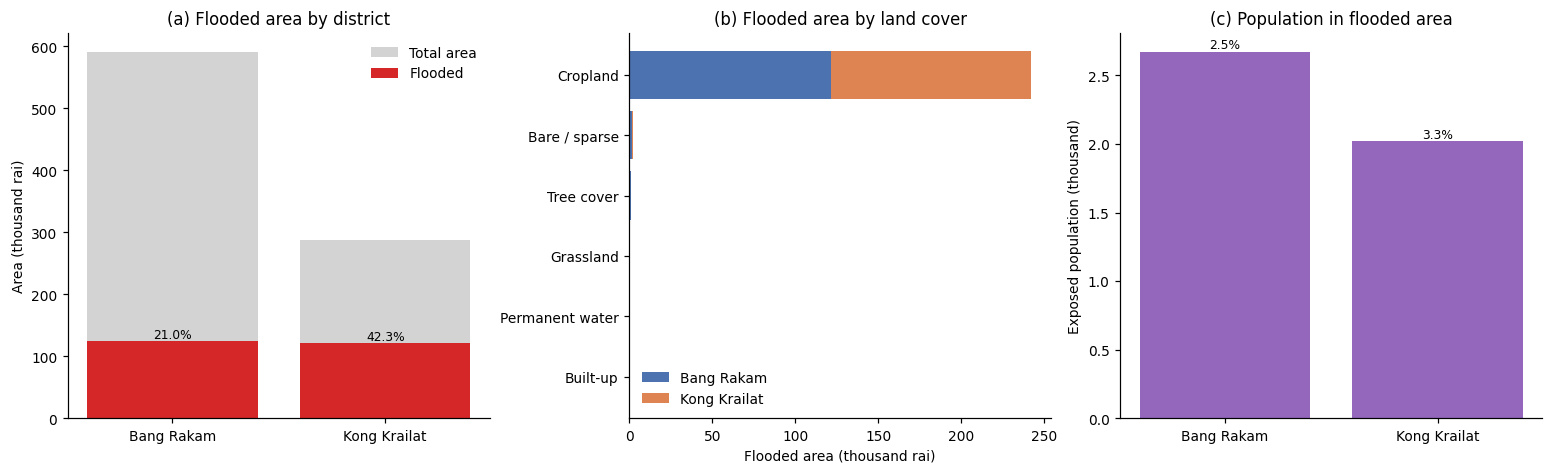

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)

# (a) พื้นที่น้ำท่วมรายอำเภอ
ax = axes[0]
ax.bar(by_amphoe['amphoe'], by_amphoe['total_rai'] / 1000, color='lightgray', label='Total area')
bars = ax.bar(by_amphoe['amphoe'], by_amphoe['flood_rai'] / 1000, color='tab:red', label='Flooded')
ax.bar_label(bars, labels=[f'{p:.1f}%' for p in by_amphoe['flood_%']], fontsize=8)
ax.set_ylabel('Area (thousand rai)'); ax.set_title('(a) Flooded area by district'); ax.legend(frameon=False)

# (b) พื้นที่น้ำท่วมตามสิ่งปกคลุมดิน แยกอำเภอ
ax = axes[1]
top = by_lulc[by_lulc['flood_rai'] > 0].head(6)
bottom = np.zeros(len(top))
for name, color in zip(names, ['#4c72b0', '#dd8452', '#55a868', '#c44e52']):
    ax.barh(top['class'], top[name] / 1000, left=bottom, color=color, label=name)
    bottom += top[name].to_numpy() / 1000
ax.invert_yaxis(); ax.set_xlabel('Flooded area (thousand rai)')
ax.set_title('(b) Flooded area by land cover'); ax.legend(frameon=False)

# (c) ประชากรในพื้นที่น้ำท่วม
ax = axes[2]
bars = ax.bar(by_pop['amphoe'], by_pop['exposed'] / 1000, color='tab:purple')
ax.bar_label(bars, labels=[f'{p:.1f}%' for p in by_pop['exposed_%']], fontsize=8)
ax.set_ylabel('Exposed population (thousand)'); ax.set_title('(c) Population in flooded area')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
su.save_fig(fig, 'fig03_damage_charts.png')
plt.show()

## 6. แผนที่น้ำท่วมจำแนกตามสิ่งปกคลุมดิน

บันทึก: outputs/fig03_flood_by_lulc.png


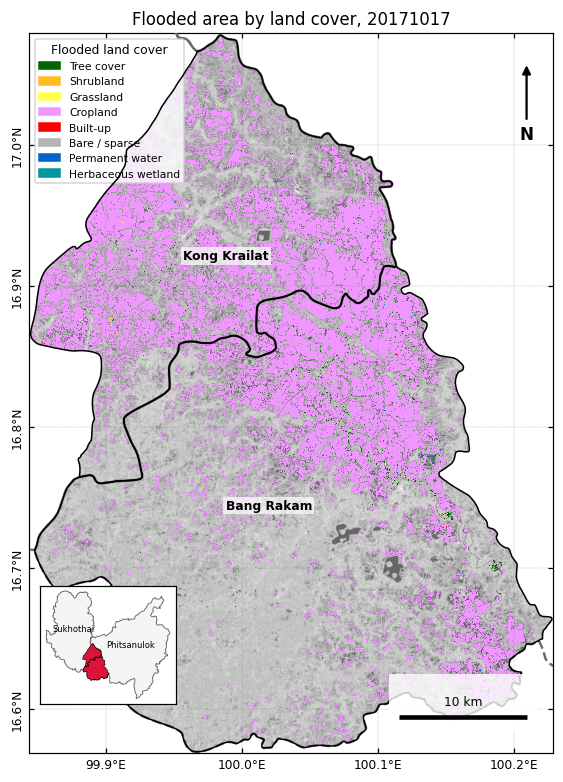

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

codes = [c for c in su.WORLDCOVER if (flood & (wc == c)).sum() * px_rai >= 1]   # คลาสที่ท่วมอย่างน้อย 1 ไร่
cmap = ListedColormap([su.WORLDCOVER[c][1] for c in codes])
index = np.full(wc.shape, np.nan)
for k, c in enumerate(codes):
    index[flood & (wc == c)] = k

fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
ax.imshow(fm['flood_img'], cmap='gray', vmin=-27, vmax=-7, alpha=0.6, extent=su.extent(grid))
ax.imshow(np.ma.masked_invalid(index), cmap=cmap, norm=BoundaryNorm(np.arange(-0.5, len(codes)), cmap.N),
          extent=su.extent(grid), interpolation='nearest')
su.journal_map(ax, grid, amphoe, province)
su.add_inset(ax, amphoe, province)
ax.legend(handles=[Patch(color=su.WORLDCOVER[c][1], label=su.WORLDCOVER[c][0]) for c in codes],
          title='Flooded land cover', loc='upper left', fontsize=7, title_fontsize=8)
ax.set_title(f'Flooded area by land cover, {su.FLOOD_TAG}')
su.save_fig(fig, 'fig03_flood_by_lulc.png')
plt.show()

In [8]:
# บันทึกตารางผลลัพธ์เป็น CSV สำหรับใช้ในรายงาน
os.makedirs('outputs', exist_ok=True)
by_amphoe.round(1).to_csv('outputs/table03_flood_by_amphoe.csv', index=False)
by_lulc.round(1).to_csv('outputs/table03_flood_by_lulc.csv', index=False)
by_pop.round(1).to_csv('outputs/table03_population_exposed.csv', index=False)
print(sorted(f for f in os.listdir('outputs') if f.startswith('table03')))

['table03_flood_by_amphoe.csv', 'table03_flood_by_lulc.csv', 'table03_population_exposed.csv']


## 7. แบบฝึกหัด

### ข้อ 1 อ่านตาราง
อำเภอใดมีพื้นที่เพาะปลูก (Cropland) ถูกน้ำท่วมมากที่สุดเป็นไร่ และอำเภอใดมีร้อยละของพื้นที่อำเภอที่ถูกท่วมสูงกว่า สองคำตอบนี้จำเป็นต้องเป็นอำเภอเดียวกันหรือไม่

<details><summary><b>เฉลย</b></summary>

```python
crop = by_lulc[by_lulc['class'] == 'Cropland'][names].iloc[0]
print('Cropland ท่วมมากสุด:', crop.idxmax(), f'{crop.max():,.0f} ไร่')
print(by_amphoe[['amphoe', 'flood_%']])
```
ไม่จำเป็นต้องเป็นอำเภอเดียวกัน อำเภอที่ใหญ่กว่าอาจมีพื้นที่ท่วมเป็นไร่มากกว่า แม้ร้อยละจะต่ำกว่า การรายงานจึงควรให้ทั้งค่าสัมบูรณ์และร้อยละ
</details>

### ข้อ 2 ผลของความละเอียดข้อมูล
ลองคำนวณประชากรในพื้นที่น้ำท่วมด้วยวิธีหยาบ คือถือว่าจุดภาพประชากรถูกท่วมทั้งจุดเมื่อ $f_i > 0$ ผลต่างจากวิธีถ่วงน้ำหนักเท่าไร

<details><summary><b>เฉลย</b></summary>

```python
weighted = (pop * frac)[pzones > 0].sum()
any_flood = pop[(pzones > 0) & (frac > 0)].sum()
print(f'ถ่วงน้ำหนัก: {weighted:,.0f} คน | นับทั้งจุดภาพ: {any_flood:,.0f} คน | เกิน {100 * (any_flood / weighted - 1):.0f}%')
```
วิธีนับทั้งจุดภาพให้ค่าสูงกว่าเสมอ เพราะจุดภาพที่ถูกท่วมเพียงบางส่วนถูกนับเต็ม ยิ่งข้อมูลประชากรหยาบ ความคลาดเคลื่อนยิ่งมาก นี่คือเหตุผลที่ UN-SPIDER ระบุความละเอียดของข้อมูลประชากรและสิ่งปกคลุมดินเป็นข้อจำกัดของการประเมินความเสียหาย
</details>

### ข้อ 3 ความไวต่อ threshold
ร้อยละของพื้นที่เพาะปลูกที่ถูกน้ำท่วม เปลี่ยนไปเท่าไรเมื่อใช้ T = −2 dB และ T = −4 dB

<details><summary><b>เฉลย</b></summary>

```python
crop_all = valid & (wc == 40)
for t in [-2, -3, -4]:
    f = su.flood_change_map(DATA, threshold=t)['flood']
    print(t, f'{100 * (f & crop_all).sum() / crop_all.sum():.1f}% ของพื้นที่เพาะปลูก')
```
ความไม่แน่นอนของ threshold ส่งต่อมาถึงตัวเลขความเสียหายโดยตรง ตัวเลขทุกตัวใน notebook นี้จึงควรรายงานเป็นช่วง
</details>

### ข้อ 4 คิดต่อ
ถ้าต้องประเมินมูลค่าความเสียหายของนาข้าวเป็นบาท ต้องมีข้อมูลอะไรเพิ่มอีกบ้าง

<details><summary><b>เฉลย</b></summary>

- แผนที่นาข้าวของปีเพาะปลูกนั้น (WorldCover ระบุได้แค่ Cropland) เช่น ข้อมูลกรมพัฒนาที่ดินหรือทะเบียนเกษตรกร
- ระยะการเจริญเติบโตของข้าวขณะน้ำท่วม เพราะความเสียหายขึ้นกับระยะ
- ความลึกและระยะเวลาที่น้ำท่วมขัง ซึ่งต้องใช้ภาพหลายช่วงเวลาและ DEM
- ผลผลิตต่อไร่และราคาข้าวในพื้นที่

ภาพ SAR สองวันให้ได้เพียง "ขอบเขต" ของน้ำท่วม ณ เวลาที่ดาวเทียมผ่าน
</details>

## สรุป
- ระบบพิกัดที่มีหน่วยเป็นเมตรทำให้คำนวณพื้นที่จากการนับจุดภาพได้โดยตรง
- รายงานทั้งค่าสัมบูรณ์ (ไร่) และร้อยละ เพราะตอบคำถามต่างกัน
- เมื่อข้อมูลมีความละเอียดต่างกัน ให้คำนวณสัดส่วนภายในจุดภาพหยาบ แทนการปรับข้อมูลละเอียดให้หยาบลงแบบ nearest

**ถัดไป:** `04` ใช้ machine learning จำแนกน้ำท่วมจากหลายแบนด์พร้อมกัน